# 3. Training from scratch with annbatch

Notebook 2 used a model someone else trained. Here we train our own, twice: an autoencoder on the cp_measure
features (a table that fits in memory), then a small image classifier on the cell crops themselves, streamed from
disk. [annbatch](https://annbatch.readthedocs.io) feeds both their mini-batches.

## Part A: an autoencoder on cp_measure features

An **autoencoder** is a neural network that squeezes its input through a narrow middle layer and then tries to
rebuild the input from it. To rebuild ~1,100 features from 32 numbers, the network has to learn which features go
together. The 32 numbers in the middle (the **latent space**) are a compact description of each cell that we can
use like any other embedding.

annbatch hands mini-batches of an AnnData to a training loop, from memory or straight from disk. We train one epoch
live (well under a minute on a laptop), then load the model that was trained to convergence beforehand.

> Cells marked **ILAN** are Ilan's annbatch part. Until they are filled in, the notebook falls back to a plain
> PyTorch `TensorDataset`, so it runs end to end.

In [1]:
TIER = "small"  # or "full"

In [2]:
from data import short_warnings

short_warnings()  # warnings stay on, printed without file paths

import time
from pathlib import Path

import anndata as ad
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn

from data import fetch, load_cells, peak_memory_gb, plot_2d, tier_file, umap_2d

torch.manual_seed(0)
t_start = time.time()
cells = load_cells(tier_file(TIER))
ckpt = torch.load(fetch("autoencoder.pt"), map_location="cpu", weights_only=True)

### The input

We use the same features the pretrained model was trained on (stored in the checkpoint), clip them at +-50 and
replace the few missing values with 0, the plate median after normalization. Cells flagged by quality control
(`obs["qc_fail"]`) are left out of training.

In [3]:
cols = cells.var_names.get_indexer(ckpt["features"])
x_all = np.clip(np.nan_to_num(np.asarray(cells.X[:, cols], dtype=np.float32)), -ckpt["clip"], ckpt["clip"])
x_train = x_all[~cells.obs["qc_fail"].to_numpy()]
print(f"{x_all.shape[1]} features, {len(x_train)} training cells")

1144 features, 11165 training cells


### The model

Encoder: features -> 256 -> 32. Decoder: 32 -> 256 -> features. The same definition is in
`scripts/train_autoencoder.py`, which trained the shipped model.

In [4]:
class AutoEncoder(nn.Module):
    def __init__(self, n_in: int, hidden: int = 256, latent: int = 32, dropout: float = 0.1):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(n_in, hidden), nn.LayerNorm(hidden), nn.GELU(), nn.Dropout(dropout),
                                     nn.Linear(hidden, latent))
        self.decoder = nn.Sequential(nn.Linear(latent, hidden), nn.LayerNorm(hidden), nn.GELU(),
                                     nn.Linear(hidden, n_in))

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z


model = AutoEncoder(x_all.shape[1], ckpt["hidden"], ckpt["latent"])
model

AutoEncoder(
  (encoder): Sequential(
    (0): Linear(in_features=1144, out_features=256, bias=True)
    (1): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.1, inplace=False)
    (4): Linear(in_features=256, out_features=32, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=32, out_features=256, bias=True)
    (1): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
    (2): GELU(approximate='none')
    (3): Linear(in_features=256, out_features=1144, bias=True)
  )
)

### Feeding the data

A data loader yields shuffled mini-batches of cells. annbatch does this for AnnData objects in memory and on disk,
fetching contiguous chunks of rows and shuffling across them.

In [5]:
# ILAN: annbatch Loader over X
# Draft from scripts/train_autoencoder.py; replace with the version you present.
BATCH_SIZE = 256
try:
    from annbatch import Loader

    def make_loader():
        return Loader(batch_size=BATCH_SIZE, chunk_size=32, preload_nchunks=64, shuffle=True, drop_last=True,
                      to="torch", preload_to_gpu=False).add_adata(ad.AnnData(X=x_train))

    def batches(loader):
        for batch in loader:
            yield batch["X"]

    loader_name = "annbatch.Loader"
except ImportError:
    make_loader = None

In [6]:
# Fallback without annbatch: a plain PyTorch TensorDataset
if make_loader is None:
    from torch.utils.data import DataLoader, TensorDataset

    def make_loader():
        return DataLoader(TensorDataset(torch.from_numpy(x_train)), batch_size=BATCH_SIZE, shuffle=True,
                          drop_last=True)

    def batches(loader):
        for (x,) in loader:
            yield x

    loader_name = "torch TensorDataset"
print("data loader:", loader_name)

data loader: annbatch.Loader


### Balancing the classes

A shuffled loader shows each class as often as it occurs. Here DMSO, the control we compare everything with, is
only about 1% of the cells, and in real screens rare compounds or cell types are easy to drown out. annbatch's
`WeightedClassSampler` draws batches whose class mix follows weights you choose. It reads whole chunks of one
class at a time, so the rows must be grouped by class (sorted here in memory; for data on disk, build the collection
with `add_adatas(..., groupby="compound")`).

In [7]:
# ILAN: class-balanced sampling with annbatch.samplers.WeightedClassSampler
import pandas as pd
from annbatch.samplers import WeightedClassSampler

compound = cells.obs["compound"].astype(str).to_numpy()[~cells.obs["qc_fail"].to_numpy()]
by_class = np.argsort(compound, kind="stable")
classes = pd.Categorical(compound[by_class])
grouped = ad.AnnData(X=x_train[by_class], obs=pd.DataFrame({"compound": classes}))

plain = Loader(batch_size=256, chunk_size=32, preload_nchunks=64, shuffle=True, drop_last=True, to="torch",
               preload_to_gpu=False, rng=np.random.default_rng(0)).add_adata(grouped)
balanced = Loader(batch_sampler=WeightedClassSampler(
    chunk_size=32, preload_nchunks=64, batch_size=256, classes=classes, num_samples=len(classes) // 256 * 256,
    drop_last=True, rng=np.random.default_rng(0)), to="torch", preload_to_gpu=False).add_adata(grouped)


def dmso_share(loader):
    names = np.concatenate([batch["obs"]["compound"].astype(str).to_numpy() for batch in loader])
    return (names == "DMSO").mean(), len(set(names))


for name, loader in [("plain shuffle", plain), ("balanced", balanced)]:
    share, n = dmso_share(loader)
    print(f"{name:>13}: DMSO is {share:.1%} of the cells seen in one pass ({n} compounds seen)")

plain shuffle: DMSO is 1.0% of the cells seen in one pass (41 compounds seen)
     balanced: DMSO is 2.9% of the cells seen in one pass (41 compounds seen)


### One epoch live

One epoch means every training cell is seen once. The loss is the mean squared error between the input features
and their reconstruction.

In [8]:
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
model.train()
t0, losses = time.time(), []
for x in batches(make_loader()):
    loss = nn.functional.mse_loss(model(x)[0], x)
    opt.zero_grad()
    loss.backward()
    opt.step()
    losses.append(loss.item())
print(f"1 epoch: {len(losses)} batches in {time.time() - t0:.1f} s, "
      f"loss {np.mean(losses[:10]):.2f} (first 10 batches) -> {np.mean(losses[-10:]):.2f} (last 10)")

1 epoch: 43 batches in 8.1 s, loss 7.48 (first 10 batches) -> 6.31 (last 10)


### The trained model

The shipped model was trained the same way until the validation loss stopped improving (several hundred epochs on
the cluster). We load its weights and compute the latent space for every cell. It matches the `X_ae` stored in the
file.

In [9]:
trained = AutoEncoder(x_all.shape[1], ckpt["hidden"], ckpt["latent"])
trained.load_state_dict(ckpt["state_dict"])
trained.eval()
with torch.no_grad():
    z = trained.encoder(torch.from_numpy(x_all)).numpy()
print(f"best validation loss during training: {ckpt['best_val_mse']:.3f}")
print(f"max |z - stored X_ae| = {np.abs(z - cells.obsm['X_ae']).max():.2e}")

best validation loss during training: 1.224
max |z - stored X_ae| = 0.00e+00


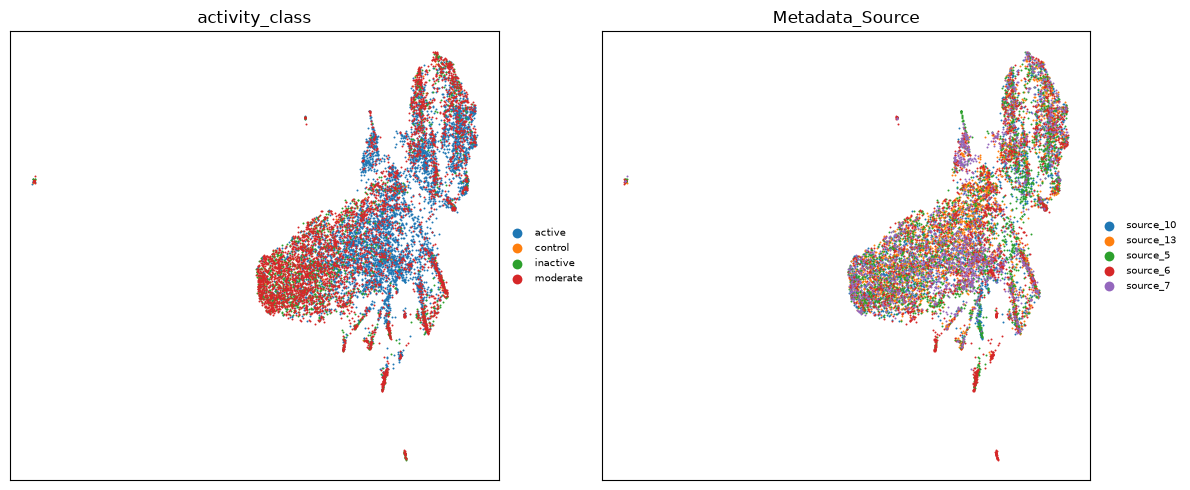

In [10]:
plot_2d(umap_2d(z), cells.obs, ["activity_class", "Metadata_Source"])
plt.tight_layout()

The 32-number latent space keeps the main structure of the 1,100 features: active compounds separate from DMSO,
and the source effect is still there. The autoencoder was never told which compound a cell got; it only learned to
compress.

## Part B: a small CNN on the crops, streamed from disk

Images are much bigger than feature tables: the small tier's crops are 0.5 GB, the full tier's 4.5 GB, and real
screens have millions of cells. So we never load them all. A **pre-shuffled collection** stores the crops in a zarr
store whose rows were shuffled once on disk; annbatch reads a few contiguous chunks of 16 cells at a time and
shuffles across them, so every mini-batch mixes compounds, plates and sources.

The task: from a crop alone, guess which of the 41 treatments (40 compounds or DMSO) the cell got. Many compounds
barely change the cells, so this is hard; chance is 1 in 41 (2.4%). The model is a small **convolutional neural
network** (CNN): three blocks of convolution, normalization and pooling turn a 5 x 48 x 48 crop (we halve the
96 px crops on the fly) into 128 numbers, and a linear layer scores the 41 classes. It has about 100,000 weights
and trains in about a minute on a laptop.

In [11]:
from torch.nn import functional as F


class TinyCNN(nn.Module):
    def __init__(self, n_classes: int, widths=(32, 64, 128)):
        super().__init__()
        layers, c_in = [], 5
        for c in widths:
            layers += [nn.Conv2d(c_in, c, 3, padding=1), nn.BatchNorm2d(c), nn.ReLU(), nn.MaxPool2d(2)]
            c_in = c
        self.features = nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.head = nn.Linear(c_in, n_classes)

    def forward(self, x):
        return self.head(self.features(x))


def to_input(x):
    """uint8 crops (B, 5, 96, 96) -> floats in [0, 1] at 48 px."""
    return F.avg_pool2d(x.float().div_(255.0), 2)

In [12]:
# ILAN: annbatch Loader over the crops of a pre-shuffled collection
# Draft from scripts/poc_annbatch_ooc.py; replace with the version you present.
import zipfile

import zarr

collection = f"data/workshop_{TIER}_collection.zarr"
zipfile.ZipFile(fetch(f"workshop_{TIER}_collection.zarr.zip")).extractall("data")
groups = [g for _, g in sorted(zarr.open(collection, mode="r").groups())]
crops = [g["obsm"]["single_cell_images"] for g in groups]  # on disk, (n, 5, 96, 96) uint8
crop_obs = [ad.io.read_elem(g["obs"])[["highlight", "Metadata_Plate"]] for g in groups]
labels = sorted(set().union(*[set(o["highlight"].astype(str)) for o in crop_obs]))
label_id = {c: i for i, c in enumerate(labels)}
print([c.shape for c in crops], "chunks", crops[0].chunks, "|", len(labels), "classes")

# hold out 10% of the plates for validation; read their crops once
plates = np.array(sorted(set().union(*[set(o["Metadata_Plate"].astype(str)) for o in crop_obs])))
val_plates = set(np.random.default_rng(0).choice(plates, round(0.1 * len(plates)), replace=False))
val_idx = [np.flatnonzero(o["Metadata_Plate"].astype(str).isin(val_plates).to_numpy()) for o in crop_obs]
val_x = to_input(torch.from_numpy(np.concatenate([c.oindex[i] for c, i in zip(crops, val_idx)])))
val_y = np.concatenate([o["highlight"].astype(str).map(label_id).to_numpy()[i] for o, i in zip(crop_obs, val_idx)])

image_loader = Loader(batch_size=128, chunk_size=16, preload_nchunks=64, shuffle=True, drop_last=True, to="torch",
                      preload_to_gpu=False, rng=np.random.default_rng(0))
image_loader.add_datasets(crops, obs=crop_obs)
print(f"{len(val_y)} validation cells on {len(val_plates)} held-out plates")

[(11244, 5, 96, 96)] chunks (16, 5, 96, 96) | 41 classes


709 validation cells on 6 held-out plates


### Plain vs class-balanced sampling

The plain loader shows each class as often as it occurs. For the class-balanced run we use annbatch's
`WeightedClassSampler` (as in Part A), which needs the rows grouped by class on disk. annbatch builds such a
collection from the h5ad in a few seconds with `add_adatas(..., groupby="compound")`.

In [13]:
# ILAN: a collection grouped by compound, for WeightedClassSampler
import shutil

import h5py
from annbatch import DatasetCollection
from annbatch.samplers import WeightedClassSampler

grouped_path = f"data/workshop_{TIER}_collection_bycompound.zarr"
if not Path(grouped_path).exists():
    t0 = time.time()
    h5 = h5py.File(tier_file(TIER), "r")
    lazy_crops = ad.experimental.read_elem_lazy(h5["obsm"]["single_cell_images"], chunks=(16, -1, -1, -1))
    DatasetCollection(zarr.open(grouped_path, mode="w")).add_adatas(
        adata_paths=[tier_file(TIER)], groupby="compound", shuffle=True, n_obs_per_chunk=16,
        load_adata=lambda path: ad.AnnData(obs=ad.io.read_elem(h5["obs"])[["compound", "highlight", "Metadata_Plate"]],
                                           obsm={"single_cell_images": lazy_crops}))
    h5.close()
    print(f"grouped collection built in {time.time() - t0:.0f} s")
g_groups = [g for _, g in sorted(zarr.open(grouped_path, mode="r").groups())]
g_crops = [g["obsm"]["single_cell_images"] for g in g_groups]
g_obs = [ad.io.read_elem(g["obs"])[["highlight", "Metadata_Plate"]] for g in g_groups]
classes = pd.Categorical(pd.concat([o["highlight"].astype(str) for o in g_obs], ignore_index=True))
n_train = sum(c.shape[0] for c in crops) - len(val_y)
balanced_loader = Loader(batch_sampler=WeightedClassSampler(
    chunk_size=16, preload_nchunks=64, batch_size=128, classes=classes, num_samples=n_train // 128 * 128,
    drop_last=True, rng=np.random.default_rng(0)), to="torch", preload_to_gpu=False)
balanced_loader.add_datasets(g_crops, obs=g_obs)

Validating groupby columns:   0%|          | 0/1 [00:00<?, ?it/s]

Validating anndatas:   0%|          | 0/1 [00:00<?, ?it/s]

Lazy loading anndatas:   0%|          | 0/1 [00:00<?, ?it/s]

Creating dataset collection:   0%|          | 0/1 [00:00<?, ?it/s]

grouped collection built in 17 s


Now we train the same network twice, a few passes each, with a one-cycle learning-rate schedule (warm up, then cool
down). Each batch arrives as `uint8` together with its `obs` rows, which carry the labels; we drop the held-out
plates and convert to floats on the fly.

In [14]:
from sklearn.metrics import balanced_accuracy_score

EPOCHS = 3


def train(loader, epochs=EPOCHS, max_lr=1e-2):
    torch.manual_seed(0)
    net = TinyCNN(len(labels))
    opt = torch.optim.AdamW(net.parameters(), lr=max_lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=max_lr, total_steps=epochs * len(loader) + 10)
    curve, history, seen, t0 = [], [], 0, time.time()
    for epoch in range(1, epochs + 1):
        net.train()
        for batch in loader:
            keep = torch.from_numpy(~batch["obs"]["Metadata_Plate"].astype(str).isin(val_plates).to_numpy())
            y = torch.from_numpy(batch["obs"]["highlight"].astype(str).map(label_id).to_numpy()[keep.numpy()])
            loss = F.cross_entropy(net(to_input(batch["X"][keep])), y)
            opt.zero_grad()
            loss.backward()
            opt.step()
            if sched.last_epoch < sched.total_steps - 1:
                sched.step()
            seen += len(y)
            curve.append((seen, loss.item()))
        net.eval()
        with torch.no_grad():
            pred = torch.cat([net(val_x[s:s + 512]) for s in range(0, len(val_x), 512)]).argmax(1).numpy()
        history.append((seen, balanced_accuracy_score(val_y, pred)))
        print(f"  epoch {epoch}: {time.time() - t0:.0f} s, held-out balanced accuracy {history[-1][1]:.3f} "
              f"(chance {1 / len(labels):.3f})")
    print(f"  {seen / (time.time() - t0):.0f} crops per second")
    return np.array(curve), np.array(history)


runs = {}
for name, loader in [("plain shuffle", image_loader), ("class-balanced", balanced_loader)]:
    print(name)
    runs[name] = train(loader)

plain shuffle


  epoch 1: 25 s, held-out balanced accuracy 0.055 (chance 0.024)


  epoch 2: 45 s, held-out balanced accuracy 0.130 (chance 0.024)


  epoch 3: 66 s, held-out balanced accuracy 0.176 (chance 0.024)
  474 crops per second
class-balanced


  epoch 1: 19 s, held-out balanced accuracy 0.056 (chance 0.024)


  epoch 2: 37 s, held-out balanced accuracy 0.059 (chance 0.024)


  epoch 3: 56 s, held-out balanced accuracy 0.119 (chance 0.024)
  524 crops per second


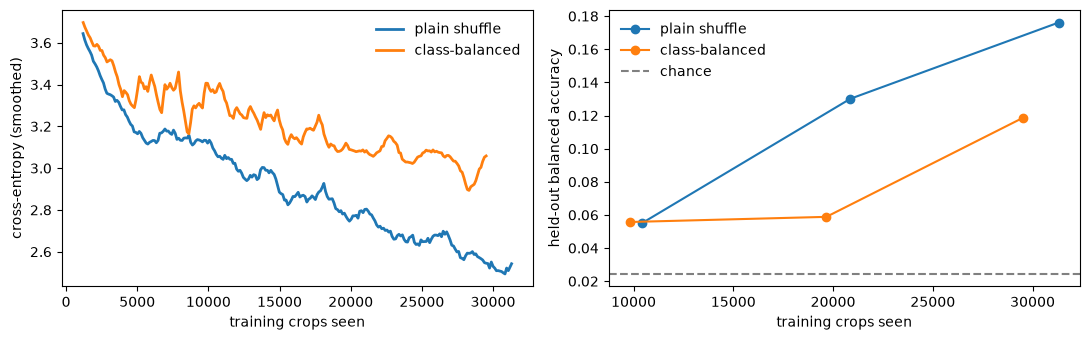

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for name, (curve, history) in runs.items():
    smooth = np.convolve(curve[:, 1], np.ones(10) / 10, mode="valid")
    axes[0].plot(curve[9:, 0], smooth, lw=2, label=name)
    axes[1].plot(history[:, 0], history[:, 1], marker="o", label=name)
axes[0].set(xlabel="training crops seen", ylabel="cross-entropy (smoothed)")
axes[1].axhline(1 / len(labels), color="grey", ls="--", label="chance")
axes[1].set(xlabel="training crops seen", ylabel="held-out balanced accuracy")
for ax in axes:
    ax.legend(frameon=False)
plt.tight_layout()

Both runs learn from crops read straight from disk: the loss falls and the held-out accuracy climbs well above
chance in a couple of minutes. On the small tier the classes are already nearly balanced (only DMSO is rare), so
balancing changes little. On the full tier, 89% of the cells are "other": with plain shuffling the network learns to
answer "other" for everything (high accuracy, chance-level balanced accuracy), while the class-balanced sampler
learns the 41 minority classes. These curves were precomputed with the same code (small tier 8 epochs, full tier
1 epoch):

![CNN training curves, plain vs balanced sampling, small and full tier](../misc/poc_losses.png)

## Scaling up

The full tier has the same layout with about 98,000 cells (4.2 GB); its crops alone would need 4.5 GB of RAM, and a
real screen has millions of cells. Nothing in Part B depends on the size: set `TIER = "full"` at the top and rerun it
to train on the full collection (a 4.9 GB download; one epoch takes about 1.5 min on 16 CPU cores). The curves
above show what to expect. The cells below show the two ways to reach the full tier's crops without loading them:
lazily from the h5ad, or streamed from its pre-shuffled collection.

They run when `TIER = "full"` or when the full collection is already unpacked in `data/`; otherwise they are
skipped and the precomputed curves (figure below) stand in. Running them downloads the full tier (4.2 GB) and
its collection (4.9 GB zipped).

![CNN training curves, plain vs balanced sampling, small and full tier](../misc/poc_losses.png)

In [16]:
RUN_SCALE = TIER == "full" or Path("data/workshop_full_collection.zarr").is_dir()
print("scale cells:", "run" if RUN_SCALE else "skipped (precomputed curves above)")

scale cells: skipped (precomputed curves above)


In [17]:
# ILAN: lazy access to the full tier's crops
if RUN_SCALE:
    import h5py

    from data import fetch

    f = h5py.File(fetch("workshop_full.h5ad"), "r")
    full_obs = ad.io.read_elem(f["obs"])
    full_imgs = ad.experimental.read_elem_lazy(f["obsm"]["single_cell_images"], chunks=(16, -1, -1, -1))
    print(full_imgs)  # (98345, 5, 96, 96) uint8, nothing read yet
    print(np.asarray(full_imgs[:16]).shape)  # reads one chunk

In [18]:
# ILAN: annbatch Loader over the pre-shuffled collection (features and images)
if RUN_SCALE:
    import zipfile

    import zarr
    from annbatch import Loader

    from data import fetch

    zipfile.ZipFile(fetch("workshop_full_collection.zarr.zip")).extractall("data")
    g = zarr.open("data/workshop_full_collection.zarr", mode="r")["dataset_0"]
    meta = ad.io.read_elem(g["obs"])
    loader = Loader(batch_size=64, chunk_size=16, preload_nchunks=64, shuffle=True, to="torch",
                    preload_to_gpu=False)
    loader.add_dataset(g["obsm"]["single_cell_images"], obs=meta)  # or g["X"] for the features
    t0 = time.time()
    for i, batch in enumerate(loader):
        if i == 0:
            print(batch["X"].shape, batch["X"].dtype, batch["obs"]["compound"].nunique(), "compounds in the batch")
        if i == 200:
            break
    print(f"{(i + 1) * 64} crops in {time.time() - t0:.1f} s")

In [19]:
print(f"runtime {time.time() - t_start:.0f} s, peak memory {peak_memory_gb():.2f} GB")

runtime 215 s, peak memory 3.67 GB
